In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('statalytical showdown(in).csv')

print("Shape:", df.shape)
print("\nFirst 5 rows:")
df.head()

Shape: (12330, 18)

First 5 rows:


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,Windows,Chrome,Delhi,Direct Traffic,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,macOS,Firefox,Delhi,Organic Search Traffic,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,Android,Chrome,Pune,Paid Search Traffic,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,Linux,Firefox,Mumbai,Referral Traffic,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,Linux,Safari,Delhi,Referral Traffic,Returning_Visitor,True,False


In [2]:
# Data types and missing values
print("Data Types & Missing Values:")
print(df.isnull().sum())
print("\nData Types:")
print(df.dtypes)

Data Types & Missing Values:
Administrative             0
Administrative_Duration    0
Informational              0
Informational_Duration     0
ProductRelated             0
ProductRelated_Duration    0
BounceRates                0
ExitRates                  0
PageValues                 0
SpecialDay                 0
Month                      0
OperatingSystems           0
Browser                    0
Region                     0
TrafficType                0
VisitorType                0
Weekend                    0
Revenue                    0
dtype: int64

Data Types:
Administrative               int64
Administrative_Duration    float64
Informational                int64
Informational_Duration     float64
ProductRelated               int64
ProductRelated_Duration    float64
BounceRates                float64
ExitRates                  float64
PageValues                 float64
SpecialDay                 float64
Month                       object
OperatingSystems            object
Bro

Revenue Distribution:
Revenue
False    10422
True      1908
Name: count, dtype: int64

False: 84.5%
True:  15.5%


C:\Users\mohit\AppData\Local\Temp\ipykernel_14644\593990910.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Revenue', data=df, palette=['#d9534f','#5cb85c'])


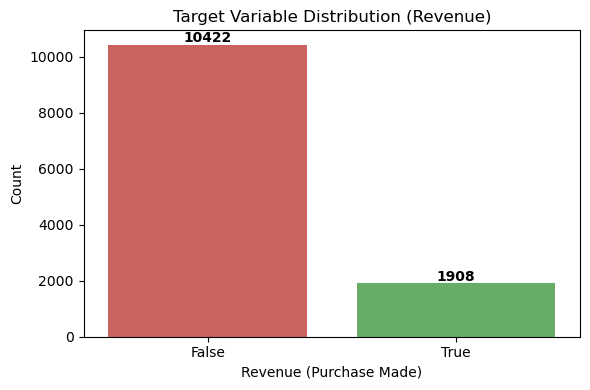

In [3]:
# Class imbalance check
revenue_counts = df['Revenue'].value_counts()
revenue_pct = df['Revenue'].value_counts(normalize=True) * 100

print("Revenue Distribution:")
print(revenue_counts)
print(f"\nFalse: {revenue_pct[False]:.1f}%")
print(f"True:  {revenue_pct[True]:.1f}%")

# Plot
plt.figure(figsize=(6,4))
sns.countplot(x='Revenue', data=df, palette=['#d9534f','#5cb85c'])
plt.title('Target Variable Distribution (Revenue)')
plt.xlabel('Revenue (Purchase Made)')
plt.ylabel('Count')
for i, count in enumerate(revenue_counts):
    plt.text(i, count + 100, str(count), ha='center', fontweight='bold')
plt.tight_layout()
plt.show()

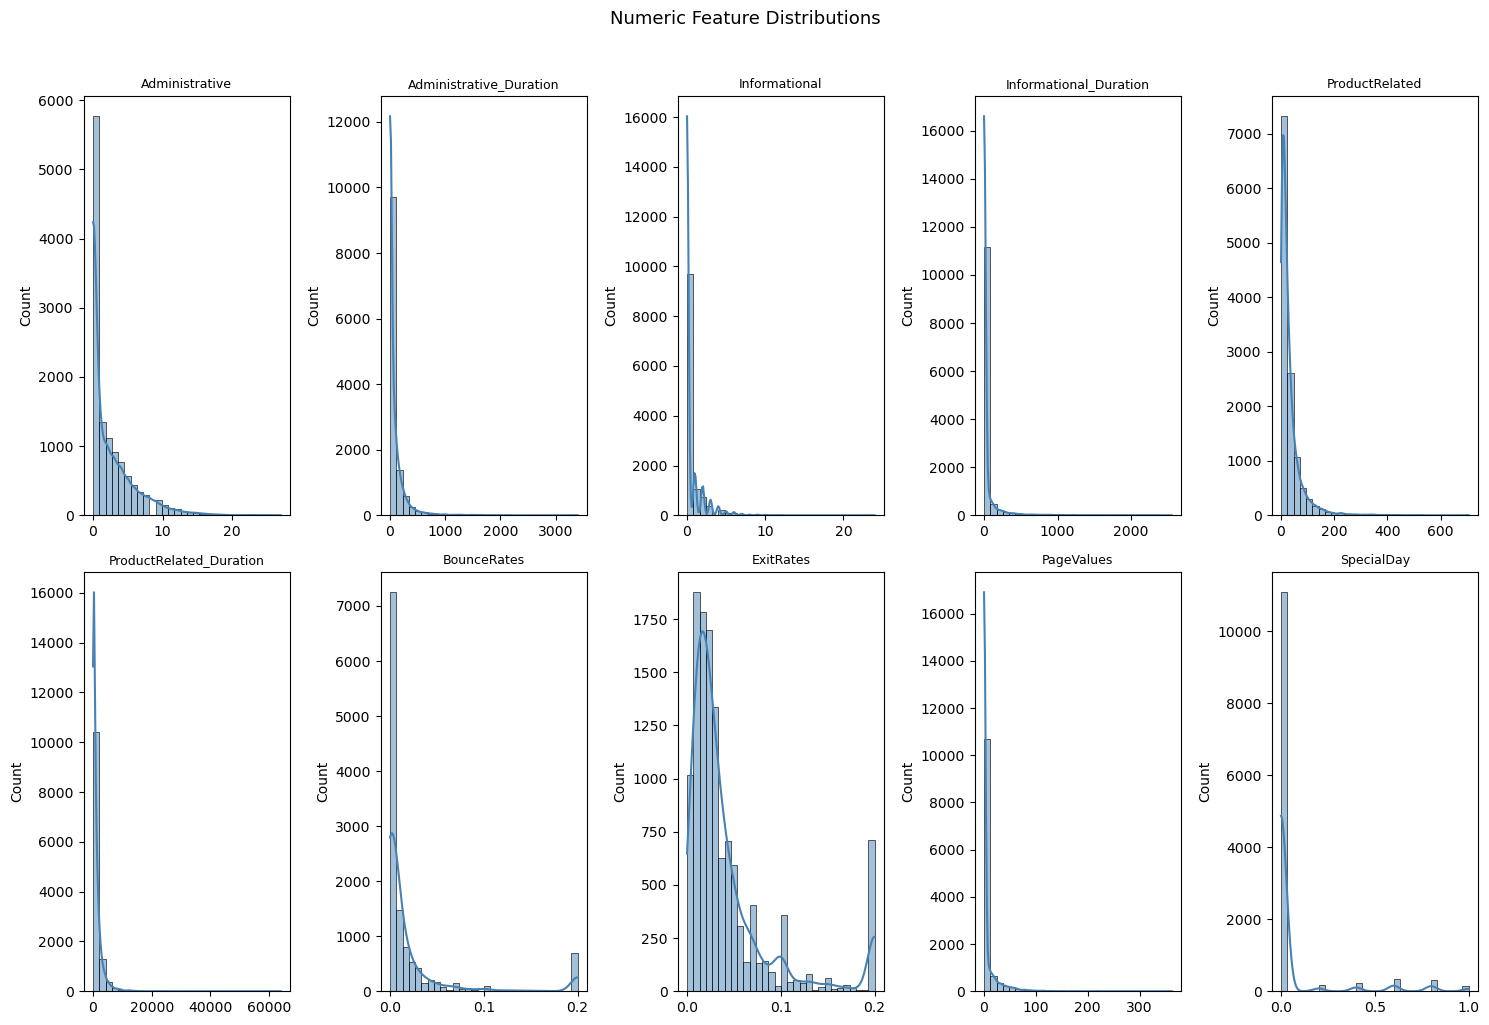

In [4]:
# Distribution of all numeric features
numeric_cols = ['Administrative', 'Administrative_Duration', 'Informational',
                'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration',
                'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay']

plt.figure(figsize=(15, 10))
for i, col in enumerate(numeric_cols):
    plt.subplot(2, 5, i+1)
    sns.histplot(df[col], bins=30, kde=True, color='steelblue')
    plt.title(col, fontsize=9)
    plt.xlabel('')
plt.suptitle('Numeric Feature Distributions', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

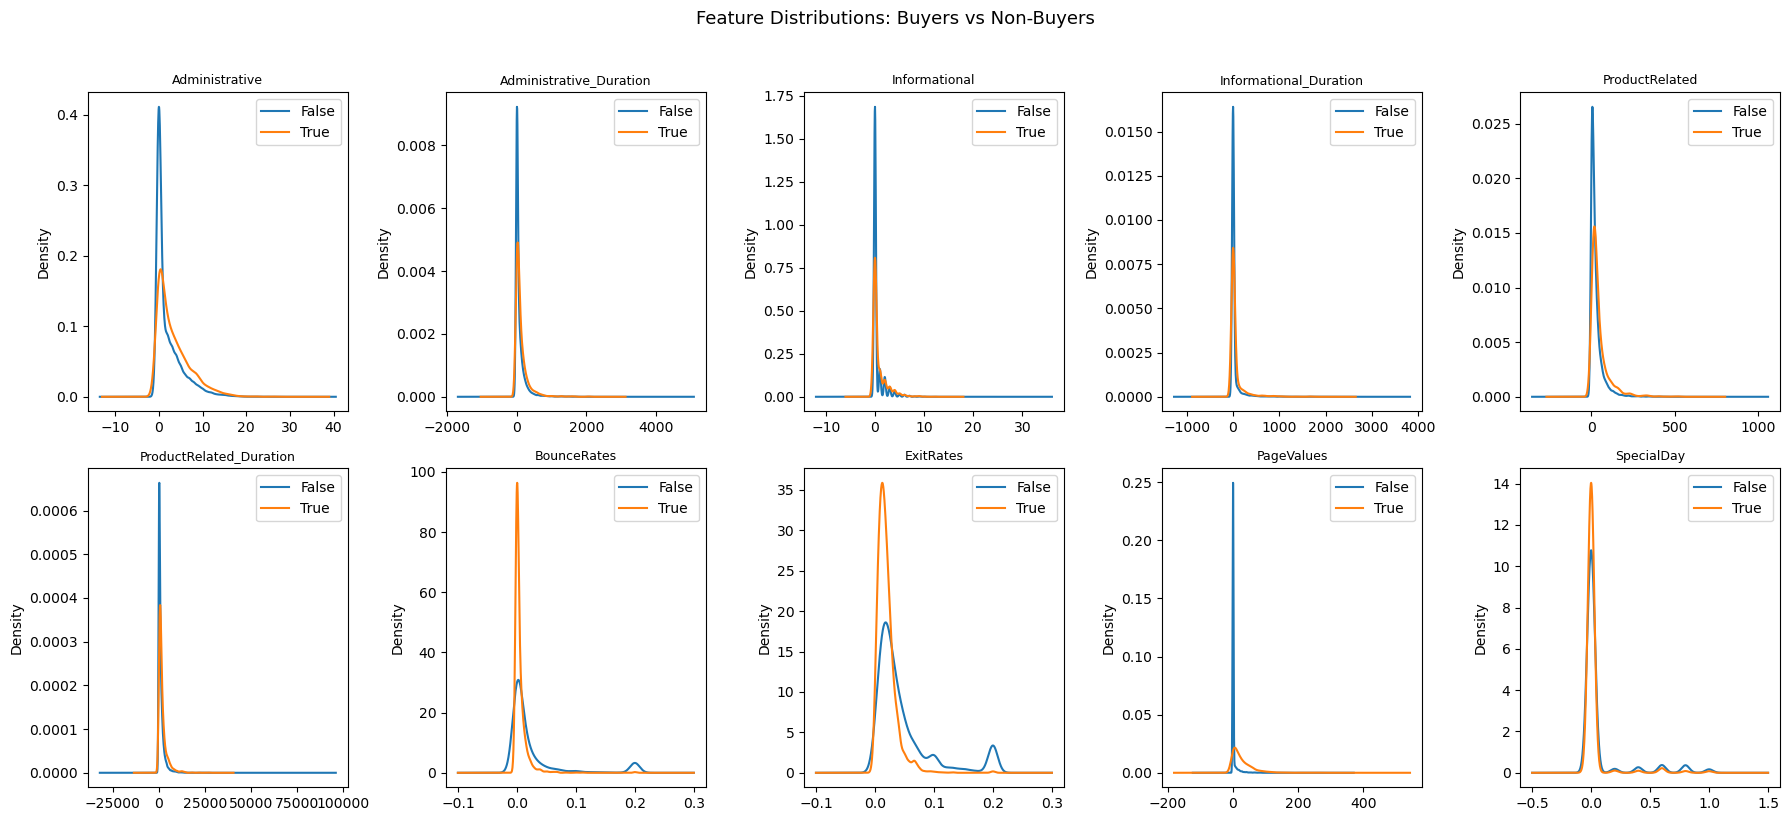

In [5]:
# Numeric features split by Revenue
fig, axes = plt.subplots(2, 5, figsize=(18, 8))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    df.groupby('Revenue')[col].plot(kind='kde', ax=axes[i], legend=True)
    axes[i].set_title(col, fontsize=9)
    axes[i].set_xlabel('')

plt.suptitle('Feature Distributions: Buyers vs Non-Buyers', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

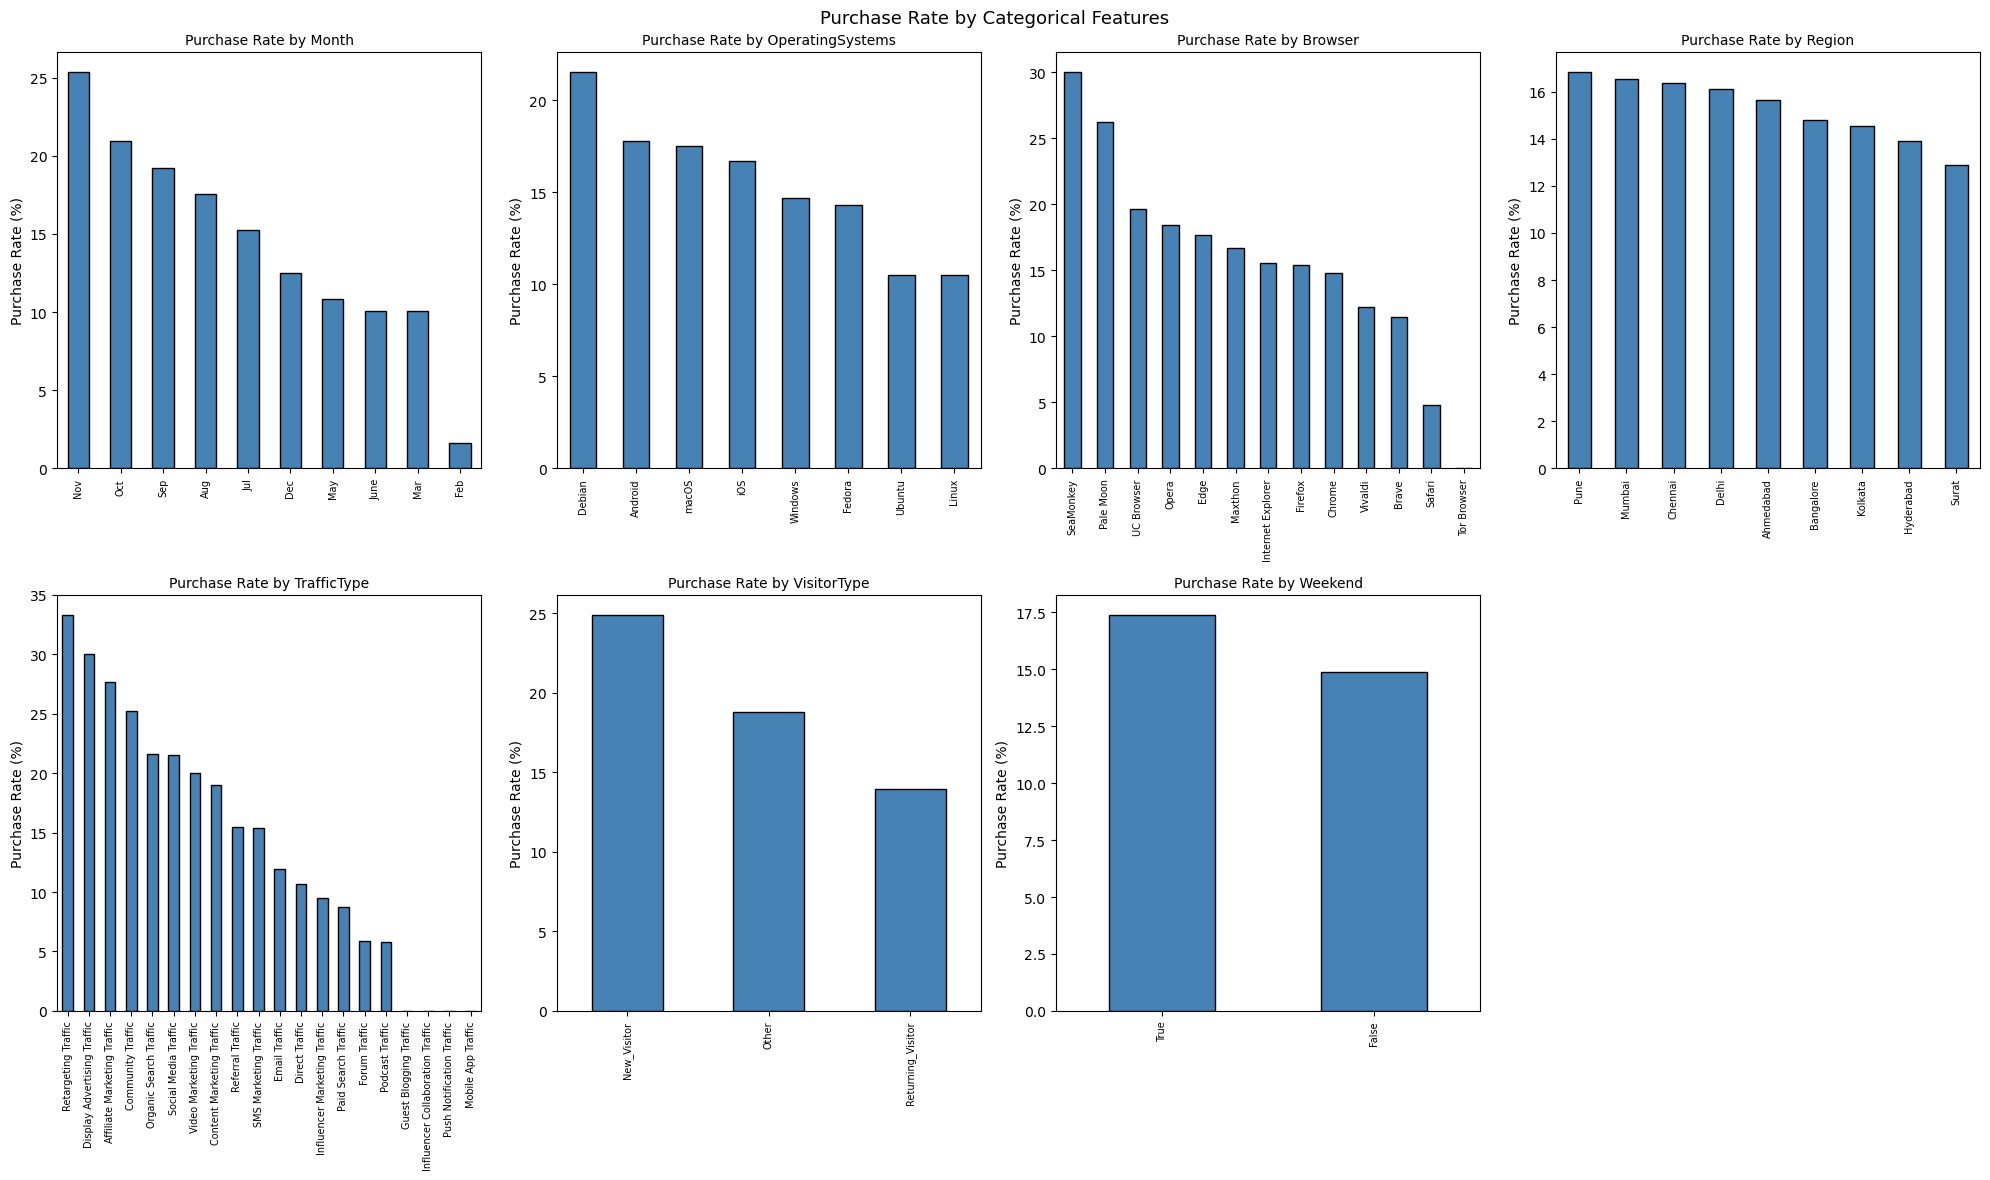

In [6]:
cat_cols = ['Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Weekend']
fig, axes = plt.subplots(2, 4, figsize=(20, 12))
axes = axes.flatten()

for i, col in enumerate(cat_cols):
    ct = df.groupby(col)['Revenue'].mean().sort_values(ascending=False) * 100
    ct.plot(kind='bar', ax=axes[i], color='steelblue', edgecolor='black')
    axes[i].set_title(f'Purchase Rate by {col}', fontsize=10)
    axes[i].set_ylabel('Purchase Rate (%)')
    axes[i].set_xlabel('')
    axes[i].tick_params(axis='x', rotation=90, labelsize=7)  # rotate 90 + smaller font

axes[-1].set_visible(False)
plt.suptitle('Purchase Rate by Categorical Features', fontsize=13)
plt.subplots_adjust(bottom=0.25)
plt.tight_layout()
plt.show()

In [7]:
for col in cat_cols:
    zero_conv = df.groupby(col)['Revenue'].mean()
    zeros = zero_conv[zero_conv == 0]
    if len(zeros) > 0:
        print(f"\n{col}:")
        print(zeros)
        # also show how many sessions they have
        print("Session counts:")
        print(df[df[col].isin(zeros.index)][col].value_counts())


Browser:
Browser
Tor Browser    0.0
Name: Revenue, dtype: float64
Session counts:
Browser
Tor Browser    1
Name: count, dtype: int64

TrafficType:
TrafficType
Guest Blogging Traffic              0.0
Influencer Collaboration Traffic    0.0
Mobile App Traffic                  0.0
Push Notification Traffic           0.0
Name: Revenue, dtype: float64
Session counts:
TrafficType
Push Notification Traffic           38
Guest Blogging Traffic              10
Mobile App Traffic                   1
Influencer Collaboration Traffic     1
Name: count, dtype: int64


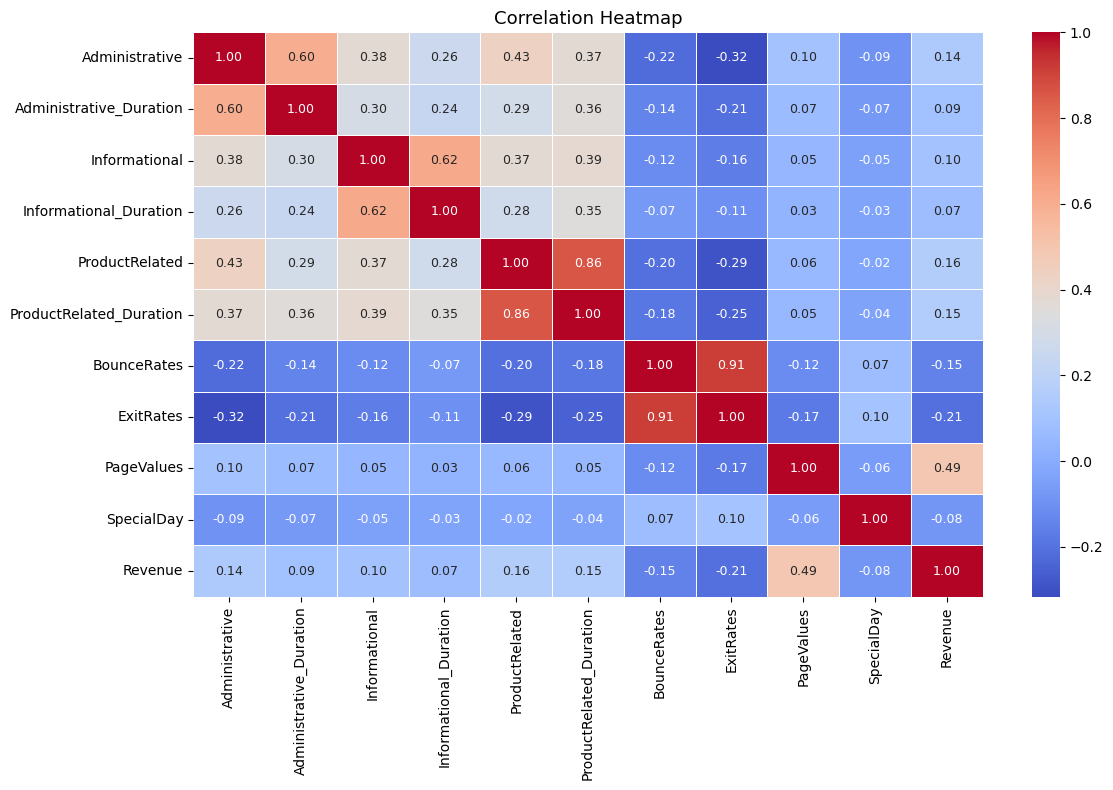

In [8]:
# Correlation heatmap of numeric features
plt.figure(figsize=(12, 8))
corr = df[numeric_cols + ['Revenue']].copy()
corr['Revenue'] = corr['Revenue'].astype(int)
sns.heatmap(corr.corr(), annot=True, fmt='.2f', cmap='coolwarm',
            linewidths=0.5, annot_kws={'size': 9})
plt.title('Correlation Heatmap', fontsize=13)
plt.tight_layout()
plt.show()

In [9]:
# Feature Engineering
df_fe = df.copy()

# Session engagement
df_fe['total_pages_visited'] = (df_fe['Administrative'] + 
                                 df_fe['Informational'] + 
                                 df_fe['ProductRelated'])

df_fe['total_duration'] = (df_fe['Administrative_Duration'] + 
                            df_fe['Informational_Duration'] + 
                            df_fe['ProductRelated_Duration'])

# Page value signal
df_fe['high_page_value'] = (df_fe['PageValues'] > 0).astype(int)

# Bounce/Exit relationship
df_fe['bounce_exit_ratio'] = df_fe['BounceRates'] / (df_fe['ExitRates'] + 0.001)

# Product focus
df_fe['product_focus_ratio'] = df_fe['ProductRelated'] / (df_fe['total_pages_visited'] + 1)

# Festive month flag
df_fe['is_festive_month'] = df_fe['Month'].isin(['Nov', 'Oct']).astype(int)

# Returning visitor flag
df_fe['is_returning_visitor'] = (df_fe['VisitorType'] == 'Returning_Visitor').astype(int)

print("New features added:")
print(df_fe[['total_pages_visited', 'total_duration', 'high_page_value', 
             'bounce_exit_ratio', 'product_focus_ratio', 
             'is_festive_month', 'is_returning_visitor']].describe())

New features added:
       total_pages_visited  total_duration  high_page_value  \
count         12330.000000    12330.000000     12330.000000   
mean             34.550203     1310.037228         0.221411   
std              46.514053     2037.801702         0.415214   
min               0.000000        0.000000         0.000000   
25%               8.000000      222.000000         0.000000   
50%              20.000000      680.000000         0.000000   
75%              42.000000     1626.908333         0.000000   
max             746.000000    69921.647230         1.000000   

       bounce_exit_ratio  product_focus_ratio  is_festive_month  \
count       12330.000000         12330.000000      12330.000000   
mean            0.282621             0.819166          0.287672   
std             0.340708             0.157396          0.452696   
min             0.000000             0.000000          0.000000   
25%             0.000000             0.750000          0.000000   
50%       

In [10]:
# Check correlation of new features with Revenue
new_features = ['total_pages_visited', 'total_duration', 'high_page_value',
                'bounce_exit_ratio', 'product_focus_ratio', 
                'is_festive_month', 'is_returning_visitor']

df_fe['Revenue_int'] = df_fe['Revenue'].astype(int)
correlations = df_fe[new_features + ['Revenue_int']].corr()['Revenue_int'].drop('Revenue_int').sort_values(ascending=False)

print("New feature correlations with Revenue:")
print(correlations)

New feature correlations with Revenue:
high_page_value         0.602517
total_pages_visited     0.164110
is_festive_month        0.161557
total_duration          0.156068
product_focus_ratio     0.087919
is_returning_visitor   -0.103843
bounce_exit_ratio      -0.132164
Name: Revenue_int, dtype: float64


In [11]:
from sklearn.preprocessing import RobustScaler, LabelEncoder
from sklearn.model_selection import train_test_split

# Define final feature set
drop_cols = ['Revenue', 'Revenue_int', 'VisitorType']  
# VisitorType dropped since we encoded it as is_returning_visitor already

X = df_fe.drop(drop_cols, axis=1)
y = df_fe['Revenue'].astype(int)

# Categorical columns to encode
cat_cols_to_encode = ['Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType']

# Label encode categoricals
le = LabelEncoder()
for col in cat_cols_to_encode:
    X[col] = le.fit_transform(X[col])

# Convert bool to int
X['Weekend'] = X['Weekend'].astype(int)

print("Feature matrix shape:", X.shape)
print("\nAny nulls:", X.isnull().sum().sum())
print("\nFirst 3 rows:")
X.head(3)

Feature matrix shape: (12330, 23)

Any nulls: 0

First 3 rows:


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,...,Region,TrafficType,Weekend,total_pages_visited,total_duration,high_page_value,bounce_exit_ratio,product_focus_ratio,is_festive_month,is_returning_visitor
0,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,...,3,3,0,1,0.0,0,0.995025,0.500000,0,1
1,0,0.0,0,0.0,2,64.0,0.0,0.1,0.0,0.0,...,3,11,0,2,64.0,0,0.000000,0.666667,0,1
2,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,...,7,12,0,1,0.0,0,0.995025,0.500000,0,1


In [12]:
# Train test split first (always split before scaling to avoid data leakage)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# RobustScaler - better than StandardScaler for skewed data with outliers
scaler = RobustScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)  # fit only on train, transform test

print("Train size:", X_train_scaled.shape)
print("Test size:", X_test_scaled.shape)
print("\nClass distribution in train:")
print(y_train.value_counts())
print("\nClass distribution in test:")
print(y_test.value_counts())

Train size: (9864, 23)
Test size: (2466, 23)

Class distribution in train:
Revenue
0    8338
1    1526
Name: count, dtype: int64

Class distribution in test:
Revenue
0    2084
1     382
Name: count, dtype: int64


In [13]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train_scaled, y_train)

print("Before SMOTE:")
print(f"Class 0: {sum(y_train == 0)}, Class 1: {sum(y_train == 1)}")
print("\nAfter SMOTE:")
print(f"Class 0: {sum(y_train_smote == 0)}, Class 1: {sum(y_train_smote == 1)}")

Before SMOTE:
Class 0: 8338, Class 1: 1526

After SMOTE:
Class 0: 8338, Class 1: 8338


In [14]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, f1_score, confusion_matrix
import warnings
warnings.filterwarnings('ignore')

# Define models - two versions each: SMOTE and class_weight
models = {
    'Logistic Regression (SMOTE)': LogisticRegression(random_state=42, max_iter=1000),
    'Logistic Regression (Class Weight)': LogisticRegression(random_state=42, max_iter=1000, class_weight='balanced'),
    'Random Forest (SMOTE)': RandomForestClassifier(random_state=42, n_estimators=100),
    'Random Forest (Class Weight)': RandomForestClassifier(random_state=42, n_estimators=100, class_weight='balanced'),
    'XGBoost (SMOTE)': XGBClassifier(random_state=42, eval_metric='logloss'),
    'XGBoost (Class Weight)': XGBClassifier(random_state=42, scale_pos_weight=8338/1526, eval_metric='logloss')
}

# Train and evaluate
results = {}

for name, model in models.items():
    if 'SMOTE' in name:
        model.fit(X_train_smote, y_train_smote)
    else:
        model.fit(X_train_scaled, y_train)
    
    y_pred = model.predict(X_test_scaled)
    f1 = f1_score(y_test, y_pred)
    results[name] = {
        'model': model,
        'y_pred': y_pred,
        'f1': f1
    }
    print(f"\n{name}")
    print(classification_report(y_test, y_pred))


Logistic Regression (SMOTE)
              precision    recall  f1-score   support

           0       0.96      0.86      0.91      2084
           1       0.52      0.81      0.63       382

    accuracy                           0.86      2466
   macro avg       0.74      0.84      0.77      2466
weighted avg       0.89      0.86      0.87      2466


Logistic Regression (Class Weight)
              precision    recall  f1-score   support

           0       0.96      0.87      0.91      2084
           1       0.53      0.80      0.64       382

    accuracy                           0.86      2466
   macro avg       0.75      0.84      0.78      2466
weighted avg       0.89      0.86      0.87      2466


Random Forest (SMOTE)
              precision    recall  f1-score   support

           0       0.94      0.92      0.93      2084
           1       0.63      0.69      0.66       382

    accuracy                           0.89      2466
   macro avg       0.78      0.81      0

In [15]:
# Comparison table
import pandas as pd

comparison = []
for name, res in results.items():
    report = classification_report(y_test, res['y_pred'], output_dict=True)
    comparison.append({
        'Model': name,
        'F1 (minority)': round(report['1']['f1-score'], 3),
        'Precision (minority)': round(report['1']['precision'], 3),
        'Recall (minority)': round(report['1']['recall'], 3),
        'Overall Accuracy': round(report['accuracy'], 3)
    })

comp_df = pd.DataFrame(comparison).sort_values('F1 (minority)', ascending=False)
print(comp_df.to_string(index=False))

                             Model  F1 (minority)  Precision (minority)  Recall (minority)  Overall Accuracy
             Random Forest (SMOTE)          0.658                 0.626              0.694             0.888
Logistic Regression (Class Weight)          0.639                 0.531              0.801             0.860
       Logistic Regression (SMOTE)          0.633                 0.521              0.806             0.855
            XGBoost (Class Weight)          0.632                 0.598              0.670             0.879
                   XGBoost (SMOTE)          0.629                 0.662              0.599             0.891
      Random Forest (Class Weight)          0.625                 0.748              0.537             0.900


In [16]:
import shap

# Use Random Forest SMOTE as final model
final_model = results['Random Forest (SMOTE)']['model']

# SHAP explainer - use a sample of test data to keep it fast
explainer = shap.TreeExplainer(final_model)
X_test_df = pd.DataFrame(X_test_scaled, columns=X.columns)

# Use 500 samples for speed
sample = X_test_df.sample(500, random_state=42)
shap_values = explainer.shap_values(sample)

# For binary classification shap_values is a list of 2 arrays
# Index [1] = SHAP values for class 1 (purchase)
print("SHAP values shape:", shap_values[1].shape)
print("Done - ready to plot")

SHAP values shape: (23, 2)
Done - ready to plot


In [17]:
# Debug check
print("Type of shap_values:", type(shap_values))
print("Length:", len(shap_values))
if isinstance(shap_values, list):
    print("shap_values[0] shape:", shap_values[0].shape)
    print("shap_values[1] shape:", shap_values[1].shape)
else:
    print("shap_values shape:", shap_values.shape)
print("\nSample shape:", sample.shape)

Type of shap_values: <class 'numpy.ndarray'>
Length: 500
shap_values shape: (500, 23, 2)

Sample shape: (500, 23)


Corrected SHAP values shape: (500, 23)


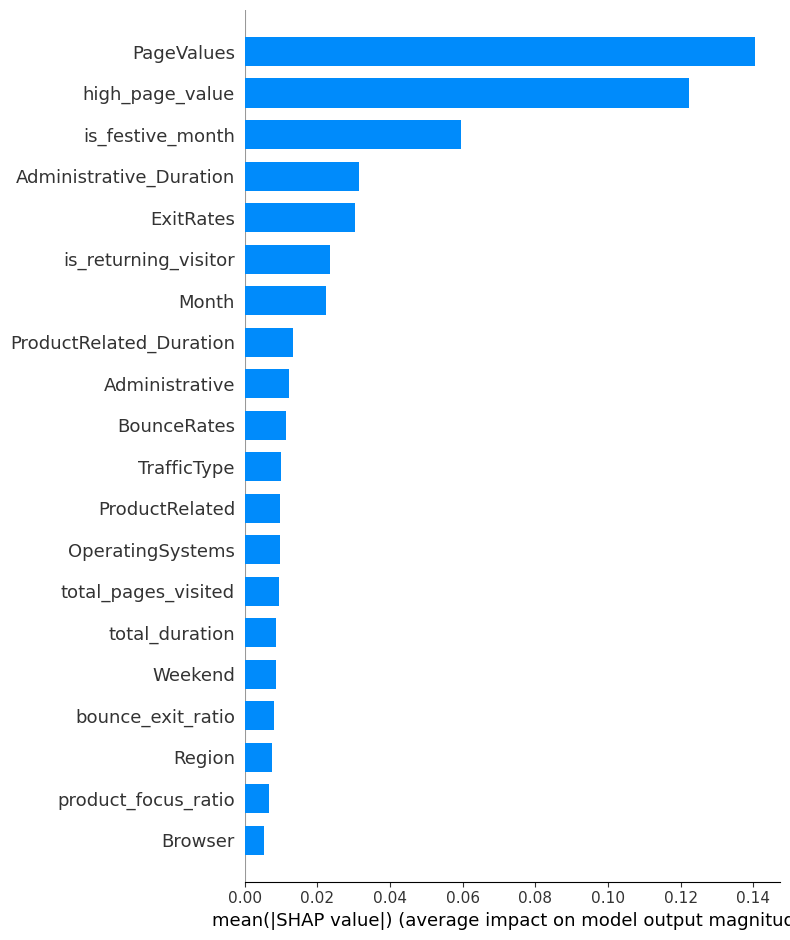

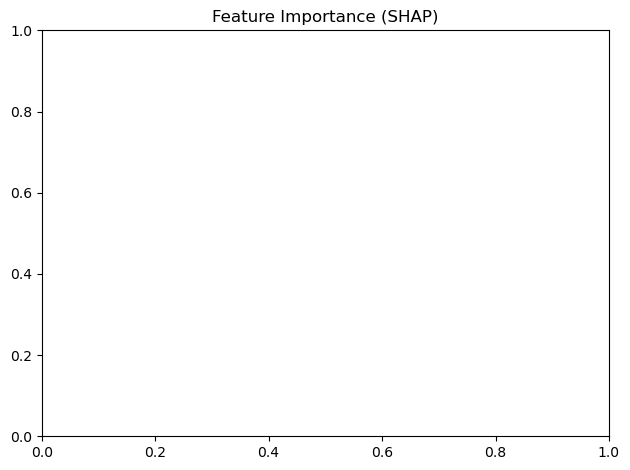

In [18]:
# Extract SHAP values for class 1 (purchase) from 3D array
shap_values_class1 = shap_values[:, :, 1]
print("Corrected SHAP values shape:", shap_values_class1.shape)

# Summary plot - overall feature importance
plt.figure()
shap.summary_plot(shap_values_class1, sample, plot_type="bar", 
                  feature_names=X.columns.tolist())
plt.title("Feature Importance (SHAP)")
plt.tight_layout()
plt.show()

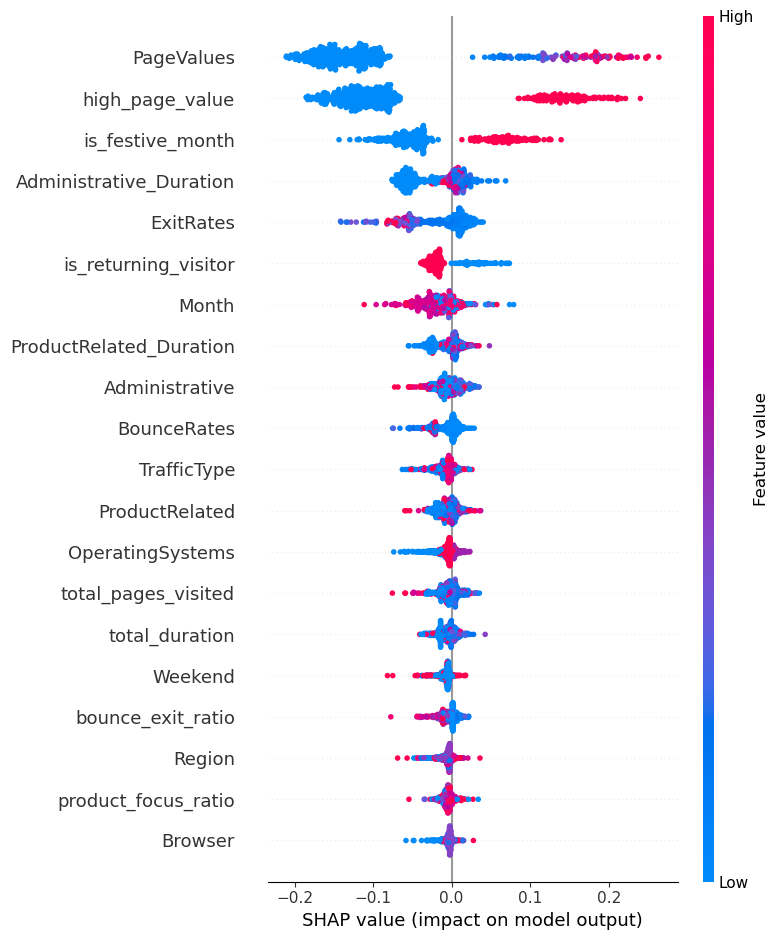

<Figure size 640x480 with 0 Axes>

In [19]:
# SHAP dot summary plot - shows direction of impact
shap.summary_plot(shap_values_class1, sample, 
                  feature_names=X.columns.tolist())
plt.tight_layout()
plt.show()

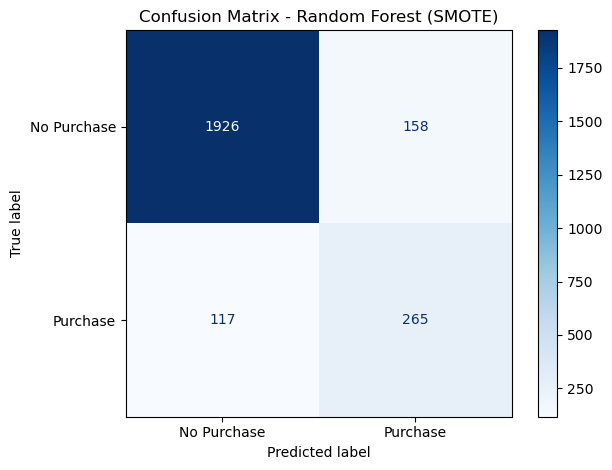


True Negatives (correctly identified non-buyers): 1926
False Positives (non-buyers flagged as buyers): 158
False Negatives (missed buyers): 117
True Positives (correctly identified buyers): 265

Out of 382 real buyers, we caught 265 (69.4%)
Out of 2084 non-buyers, we incorrectly flagged 158 (7.6%)


In [20]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Final model predictions
final_preds = results['Random Forest (SMOTE)']['y_pred']

# Plot confusion matrix
cm = confusion_matrix(y_test, final_preds)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, 
                               display_labels=['No Purchase', 'Purchase'])
disp.plot(cmap='Blues')
plt.title('Confusion Matrix - Random Forest (SMOTE)')
plt.tight_layout()
plt.show()

# Print what the numbers mean in business terms
tn, fp, fn, tp = cm.ravel()
print(f"\nTrue Negatives (correctly identified non-buyers): {tn}")
print(f"False Positives (non-buyers flagged as buyers): {fp}")
print(f"False Negatives (missed buyers): {fn}")
print(f"True Positives (correctly identified buyers): {tp}")
print(f"\nOut of {tp+fn} real buyers, we caught {tp} ({tp/(tp+fn)*100:.1f}%)")
print(f"Out of {tn+fp} non-buyers, we incorrectly flagged {fp} ({fp/(tn+fp)*100:.1f}%)")

In [21]:
from sklearn.metrics import classification_report

print("="*50)
print("FINAL MODEL: Random Forest (SMOTE)")
print("="*50)
print(f"\nClass Imbalance Handling: SMOTE")
print(f"Train size: {X_train_smote.shape[0]} samples (after SMOTE)")
print(f"Test size: {X_test_scaled.shape[0]} samples")
print("\nClassification Report:")
print(classification_report(y_test, final_preds, 
                            target_names=['No Purchase', 'Purchase']))
print("\nKey Metrics (Purchase class):")
report = classification_report(y_test, final_preds, 
                               target_names=['No Purchase', 'Purchase'],
                               output_dict=True)
print(f"  F1 Score:  {report['Purchase']['f1-score']:.3f}")
print(f"  Precision: {report['Purchase']['precision']:.3f}")
print(f"  Recall:    {report['Purchase']['recall']:.3f}")

FINAL MODEL: Random Forest (SMOTE)

Class Imbalance Handling: SMOTE
Train size: 16676 samples (after SMOTE)
Test size: 2466 samples

Classification Report:
              precision    recall  f1-score   support

 No Purchase       0.94      0.92      0.93      2084
    Purchase       0.63      0.69      0.66       382

    accuracy                           0.89      2466
   macro avg       0.78      0.81      0.80      2466
weighted avg       0.89      0.89      0.89      2466


Key Metrics (Purchase class):
  F1 Score:  0.658
  Precision: 0.626
  Recall:    0.694


In [22]:
import pickle

# Save model and scaler
with open('purchase_intention_model.pkl', 'wb') as f:
    pickle.dump(final_model, f)

with open('scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)

print("Model saved: purchase_intention_model.pkl")
print("Scaler saved: scaler.pkl")

Model saved: purchase_intention_model.pkl
Scaler saved: scaler.pkl


In [23]:
import matplotlib.pyplot as plt
import seaborn as sns
import os

os.makedirs('charts', exist_ok=True)

# Chart 1: Class Imbalance
revenue_counts = df['Revenue'].value_counts()
plt.figure(figsize=(6,4))
sns.countplot(x='Revenue', data=df, palette=['#d9534f','#5cb85c'])
plt.title('Target Variable Distribution (Revenue)')
plt.xlabel('Revenue (Purchase Made)')
plt.ylabel('Count')
for i, count in enumerate(revenue_counts):
    plt.text(i, count + 100, str(count), ha='center', fontweight='bold')
plt.tight_layout()
plt.savefig('charts/class_imbalance.png', dpi=150, bbox_inches='tight')
plt.close()

# Chart 2: Purchase Rate by Month
plt.figure(figsize=(8,4))
month_conv = df.groupby('Month')['Revenue'].mean().sort_values(ascending=False) * 100
month_conv.plot(kind='bar', color='steelblue', edgecolor='black')
plt.title('Purchase Rate by Month (%)')
plt.ylabel('Purchase Rate (%)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('charts/purchase_by_month.png', dpi=150, bbox_inches='tight')
plt.close()

# Chart 3: Purchase Rate by Traffic Type
plt.figure(figsize=(10,4))
traffic_conv = df.groupby('TrafficType')['Revenue'].mean().sort_values(ascending=False) * 100
traffic_conv.plot(kind='bar', color='steelblue', edgecolor='black')
plt.title('Purchase Rate by Traffic Type (%)')
plt.ylabel('Purchase Rate (%)')
plt.xticks(rotation=90, fontsize=7)
plt.tight_layout()
plt.savefig('charts/purchase_by_traffic.png', dpi=150, bbox_inches='tight')
plt.close()

# Chart 4: Purchase Rate by Visitor Type
plt.figure(figsize=(6,4))
visitor_conv = df.groupby('VisitorType')['Revenue'].mean().sort_values(ascending=False) * 100
visitor_conv.plot(kind='bar', color='steelblue', edgecolor='black')
plt.title('Purchase Rate by Visitor Type (%)')
plt.ylabel('Purchase Rate (%)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('charts/purchase_by_visitor.png', dpi=150, bbox_inches='tight')
plt.close()

# Chart 5: SHAP bar plot
plt.figure()
shap.summary_plot(shap_values_class1, sample,
                  plot_type="bar",
                  feature_names=X.columns.tolist(),
                  show=False)
plt.tight_layout()
plt.savefig('charts/shap_bar.png', dpi=150, bbox_inches='tight')
plt.close()

# Chart 6: Confusion Matrix
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
cm = confusion_matrix(y_test, final_preds)
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                               display_labels=['No Purchase', 'Purchase'])
disp.plot(cmap='Blues')
plt.title('Confusion Matrix - Random Forest (SMOTE)')
plt.tight_layout()
plt.savefig('charts/confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.close()

print("All charts saved in charts/ folder")
print(os.listdir('charts'))

All charts saved in charts/ folder
['class_imbalance.png', 'confusion_matrix.png', 'purchase_by_month.png', 'purchase_by_traffic.png', 'purchase_by_visitor.png', 'shap_bar.png']
